Boundary Value Problems for ODEs

By Pablo Angulo, Fabricio Macià and Daniel Sánchez-Mendoza for ETSIN@UPM

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integ

# Boundary value problems (BVPs) for ordinary differential equations (ODEs)

When dealing with BVPs the independent variable _typically_ does not represent time, but rather a spatial dimension. Although they are not common, there are some BVPs of interest with time as the independent variable.  

We start with a single second-order ODE:
$$
y''(x) = f(x,y(x),y'(x)),
$$
defined for $x$ in the interval $[a,b]$. 

A **BVP** for this ODE consists of finding a solution $y(x)$ of the ODE that takes some given values at the ends of the interval:

$$
y''(x) = f(x,y(x),y'(x)),\quad a\leq x\leq b,\quad y(a)=\alpha,\quad y(b)=\beta.
$$

The conditions 

$$y(a)=\alpha,\quad y(b)=\beta,$$

are called **boundary conditions**. These type of conditions are known as Dirichlet boundary conditions. 

They are not the only type of boundary conditions that we can encounter. Neumann boundary conditions

$$y'(a)=\alpha,\quad y'(b)=\beta,$$

are very common. There are also Robin boundary conditions

$$y'(a)=\alpha y(a), \quad y'(b)=\beta y(b),$$

and even combinations of Dirichlet, Neumann and Robin boundary conditions.

It is important to compare the BVP with the initial value problem (IVP) for the same ODE. Let us remember that the IVP consists of finding the solution of the ODE that satisfies that $y(x_0)$ and $y'(x_0)$ take some given values at some point $x_0\in [a,b]$. If $x_0=a$ this is nothing more than:

$$
y''(x) = f(x,y(x),y'(x)),\quad a\leq x\leq b,\quad y(a)=\alpha,\quad y'(a)=\beta.
$$

The __theory__ of BVPs is different from that of IVPs. Very regular BVPs may have more than one solution, or none at all. _A unique solution of the BVP presented at the beginning of this notebook is guaranteed_ when $f$ is differentiable with respect to the variables $y,y'$, and its derivatives satisfy
 - $\frac{\partial f}{\partial y} > 0,$
 - $|\frac{\partial f}{\partial y'}| < M.$

## Example

We represent the vertical displacement of a horizontal beam by a function $w(x)$ that indicates the vertical displacement at position $x$ measured from the left end of the beam.

![](Beam.png)

The following equation models the vertical displacement $w$ of a beam with homogeneous load and clamped at both ends:

$$
w''(x) = \frac{S}{EI}w(x) - \frac{q}{2EI}x(x-l)\quad 0\leq x\leq l, \quad w(0)=w(l)=0,
$$

where
 - $l$: length of the beam,
 - $E$: elastic modulus of the beam,
 - $I$: moment of inertia of the beam section,
 - $S$: horizontal tension at the ends of the beam,
 - $q$: beam load per unit length.

We set the values ​​$l=120$, $E=3\cdot 10^{7}$, $I=625$, $S=1000$, $q=100$  (in compatible units that we do not specify).

The displacement is expected to satisfy $w(x)\leq 0$ as shown in the figure.

## `integ.solve_bvp`

We solve the problem with `integ.solve_bvp`, a method from the `scipy` library to solve boundary problems _in one spatial dimension_. The syntax is similar but not as is intuitive as that of `integ.solve_ivp`.
```python
integ.solve_bvp(
    fun, # function that defines the differential equation
    bc, # function that defines boundary conditions
    xs, # an array with values ​​for the independent variable x
    ys # an "initial guess" for the y values ​​at the xs points
)
```

In [6]:
integ.solve_bvp?

In [3]:
l = 120
E = 3e7
I = 625
S = 1e3
q = 100


def fun(x, ys):
    "Defines the ODE"
    y, yp = ys
    return [yp, (S / (E * I)) * y - (q / (2 * E * I)) * x * (x - l)]


# Boundary conditions
a, b = 0, l
alpha, beta = 0, 0


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb = vals_b
    return np.array([ya - alpha, yb - beta])

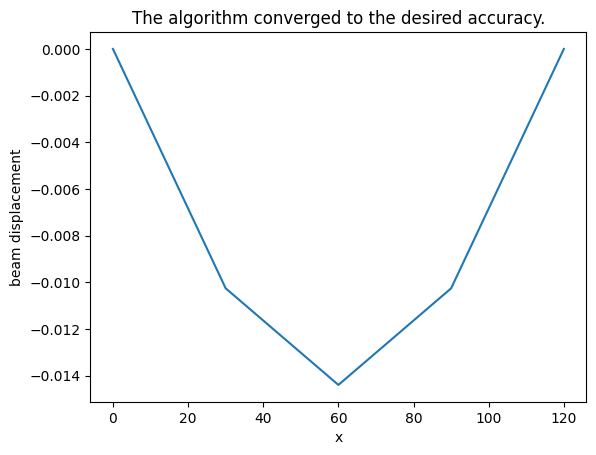

In [4]:
N = 5
xs = np.linspace(0, l, N)
ys = np.zeros((2, N))
sol = integ.solve_bvp(fun, bc, xs, ys)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"], sol["y"][0, :])
plt.show()

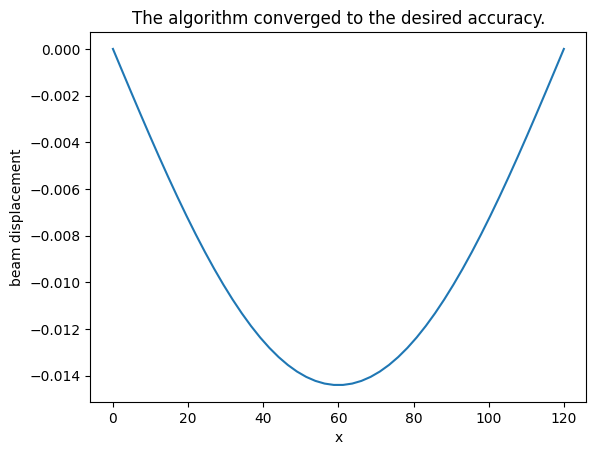

In [5]:
# We repeat for N=50
N = 50
xs = np.linspace(0, l, N)
ys = np.zeros((2, N))
sol = integ.solve_bvp(fun, bc, xs, ys)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"], sol["y"][0, :])
plt.show()

### Exercise 1:

A finer analysis allows us to improve the model described by the equation we have just analyzed:
$$
w''(x) = \frac{S}{EI}w(x) - \frac{q}{2EI}x(x-l),\quad 0\leq x\leq l.
$$

Below, we have another equation that also models the displacements of a beam clamped at the ends, under a uniform load:

$$
\frac{w''(x)}{(1 + w'(x)^2)^{3/2}} = \frac{S}{EI}w(x) - \frac{q}{2EI }x(x-l), 0\leq x\leq l.
$$

Unlike the first, this equation is not linear and is a more realistic model for the beam displacements.

However, it is known that the equation in the previous section is a good approximation if the displacements are small.

1. Solve the two equations with the same values ​​of the constants:

    $l=120$, $E=3\cdot 10^{7}$, $I=625$, $S=1000$, , $q=100$.

    Calculate the maximum difference between the solutions of the two BVPs.
    
2. Repeat the previous question for a load $q=100000$.

In [19]:
l = 120
E = 3e7
I = 625
S = 1e3
q = 100


def fun2(x, ys):
    "Defines the ODE"
    y, yp=ys
    return [yp, ((1+yp**2)**(3/2))*((S / (E * I)) * y - (q / (2 * E * I)) * x * (x - l))]


# Boundary conditions
a, b = 0, l
alpha, beta = 0, 0


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb = vals_b
    return np.array([ya - alpha, yb - beta])


l = 120
E = 3e7
I = 625
S = 1e3
q = 100000


def fun3(x, ys):
    "Defines the ODE"
    y, yp=ys
    return [yp, ((1+yp**2)**(3/2))*((S / (E * I)) * y - (q / (2 * E * I)) * x * (x - l))]


# Boundary conditions
a, b = 0, l
alpha, beta = 0, 0


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb = vals_b
    return np.array([ya - alpha, yb - beta])

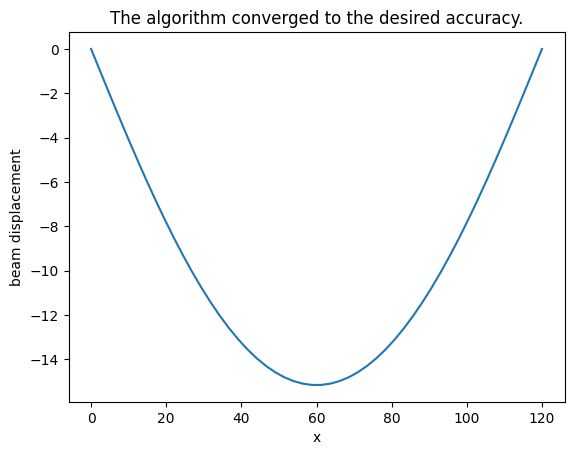

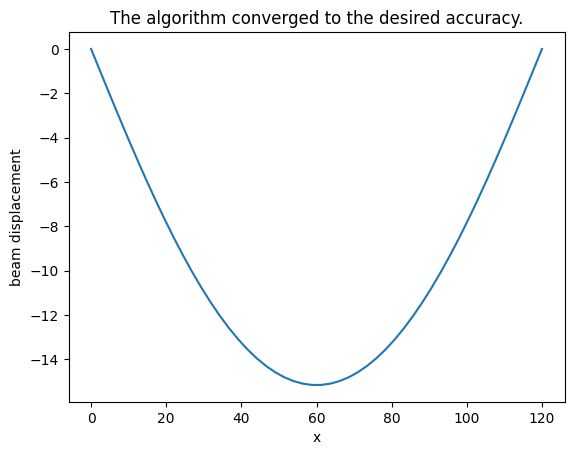

In [22]:
N = 50
xs = np.linspace(0, l, N)
ys = np.zeros((2, N))
sol2 = integ.solve_bvp(fun2, bc, xs, ys)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol2["x"], sol["y"][0, :])
plt.show()

N = 50
xs = np.linspace(0, l, N)
ys = np.zeros((2, N))
sol3 = integ.solve_bvp(fun3, bc, xs, ys)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol3["x"], sol["y"][0, :])
plt.show()

### Exercise 2:

Solve the BVP

$$-\epsilon^2 u''(x) + x^2 u(x) = 1,\quad -1\leq x \leq 1,\quad u(-1) = u(1) = 0,$$

with $\epsilon=1$ and graph its solution.

Repeat this exercise taking $\epsilon = 10^{-n}$ with $n=2,3,4,5$. Graph the corresponding solutions in the same plot.